In [1]:
import torch
from datasets import load_from_disk
import pickle as pkl
from umap import UMAP
from openTSNE import TSNE
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
import numpy as np
from typing import cast

#device = "cuda" if torch.cuda.is_available() else "cpu"
device = "cpu"

In [2]:
# loading the dataset BoghdadyJR/radiology from local backup
ds_rad = load_from_disk("./datasets/radiology/test")

In [3]:
# loading the dataset ROCOv2 from local backup
ds_roco = load_from_disk("./datasets/roco/test")
with open("./datasets/roco/test/cui.pkl", "rb") as f:
    ds_roco_cui: list[str] = pkl.load(f)

In [4]:
# loading pre-computed embeddings (i.e. the model applied to images, captions, and concepts of the datasets)
with open("./datasets/roco/test/image_embeddings.pkl", "rb") as f:
    roco_image_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/caption_embeddings.pkl", "rb") as f:
    roco_caption_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/concept_embeddings.pkl", "rb") as f:
    roco_concept_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/caption_concept_embeddings.pkl", "rb") as f:
    roco_caption_concept_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/cui_embeddings.pkl", "rb") as f:
    roco_cui_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/radiology/test/image_embeddings.pkl", "rb") as f:
    rad_image_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/radiology/test/caption_embeddings.pkl", "rb") as f:
    rad_caption_embeddings: torch.Tensor = pkl.load(f)
logit_scale = 85.2322769165039 # taken from model output, seems to be fixed for any model input

In [5]:
umap_roco_image = UMAP(
    min_dist=0.5,
    n_neighbors=50,
    n_components=2,
    metric="cosine",
    init="pca",
    random_state=42,
    compatibility_layout=True,
    n_jobs=1,
).fit(roco_image_embeddings)
umap_rad_image = UMAP(
    min_dist=0.5,
    n_neighbors=50,
    n_components=2,
    metric="cosine",
    init="pca",
    random_state=42,
    compatibility_layout=True,
    n_jobs=1,
).fit(rad_image_embeddings)
tsne_roco_image = TSNE(
    n_components=2,
    perplexity=5,
    initialization="pca",
    random_state=42,
).fit(roco_image_embeddings)
tsne_rad_image = TSNE(
    n_components=2,
    perplexity=5,
    initialization="pca",
    random_state=42,
).fit(rad_image_embeddings)

In [6]:
ds_roco[0]

{'id': 'ROCOv2_2023_test_000001',
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=653x658>,
 'concepts': [776, 368],
 'concepts_manual': [776],
 'caption': 'CT chest axial view showing a huge ascending aortic aneurysm (*).'}

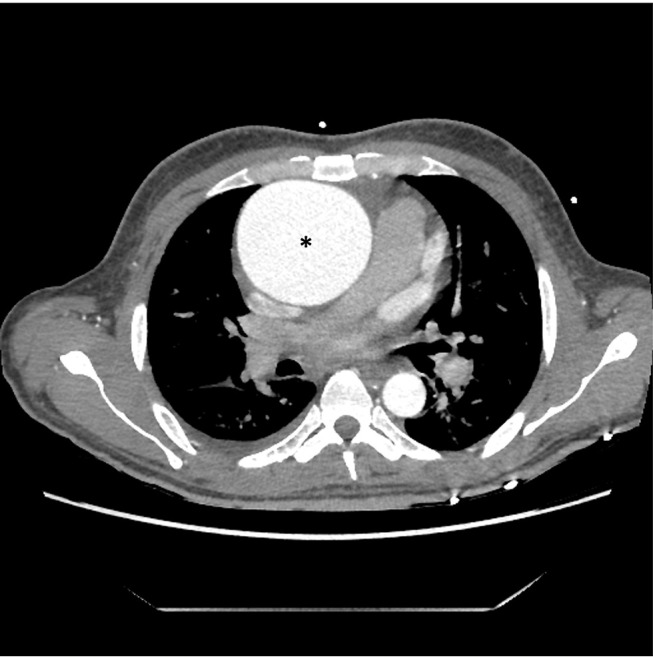

In [7]:
ds_roco[0]['image']

The model architecture:

![CLIP model architecture](https://media.geeksforgeeks.org/wp-content/uploads/20260618142010409353/image_1.webp)

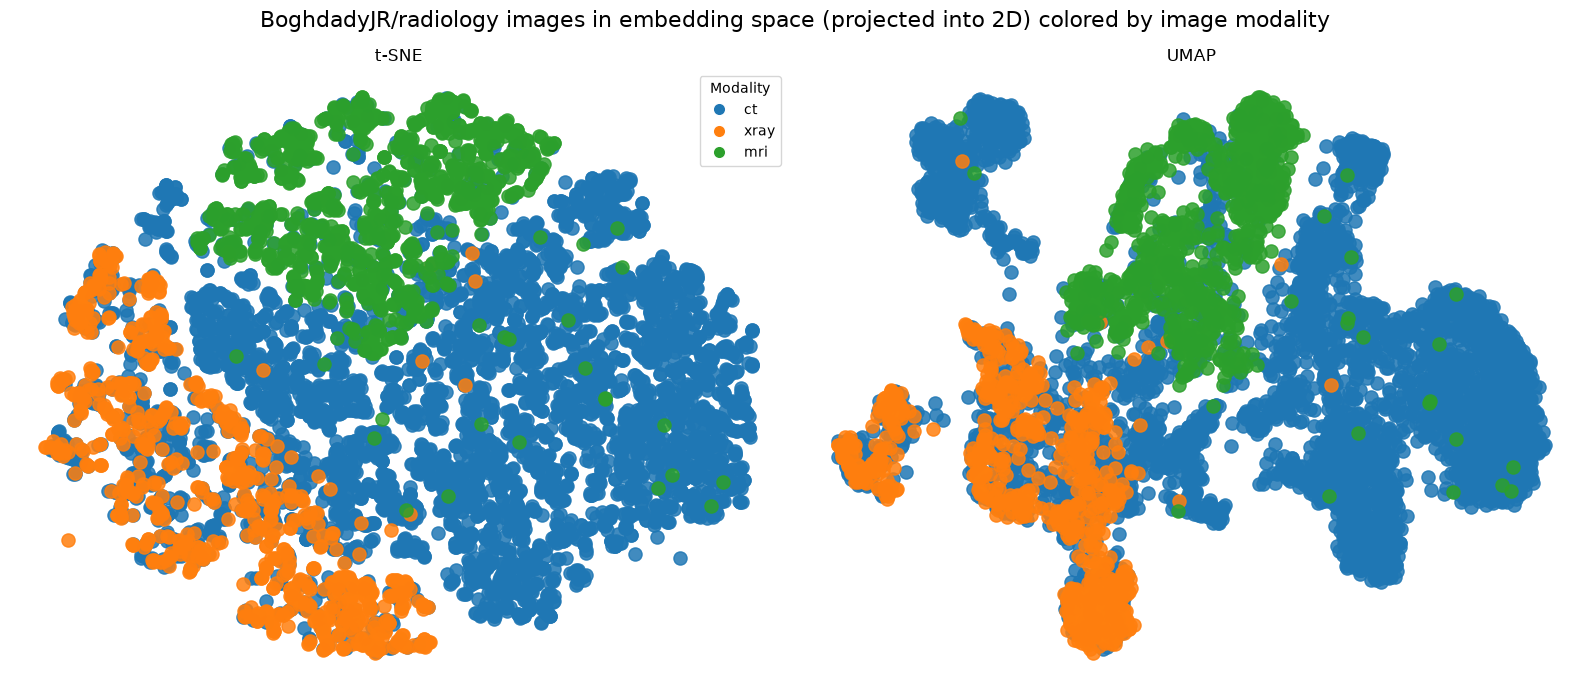

In [8]:
# images plotted in embedding space projected into 2d
# colored by image modality
samples = len(ds_rad)

embeddings = rad_image_embeddings[:samples].cpu().numpy()
modalities = ds_rad[:samples]["modality"]

tsne_embeddings = tsne_rad_image.transform(embeddings)
umap_embeddings = umap_rad_image.transform(embeddings)

unique_modalities = list(dict.fromkeys(modalities))
colors = plt.cm.tab10(range(len(unique_modalities)))
color_map = dict(zip(unique_modalities, colors))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, projected, title in zip(
    axes,
    [tsne_embeddings, umap_embeddings],
    ["t-SNE", "UMAP"],
):
    for modality in unique_modalities:
        mask = [m == modality for m in modalities]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[modality]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(title)
    ax.set_axis_off()

modality_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=modality,
        markerfacecolor=color_map[modality],
        markersize=9,
    )
    for modality in unique_modalities
]

axes[0].legend(handles=modality_handles, title="Modality", loc="best")
fig.suptitle('BoghdadyJR/radiology images in embedding space (projected into 2D) colored by image modality', fontsize=16)

plt.tight_layout()
plt.show()

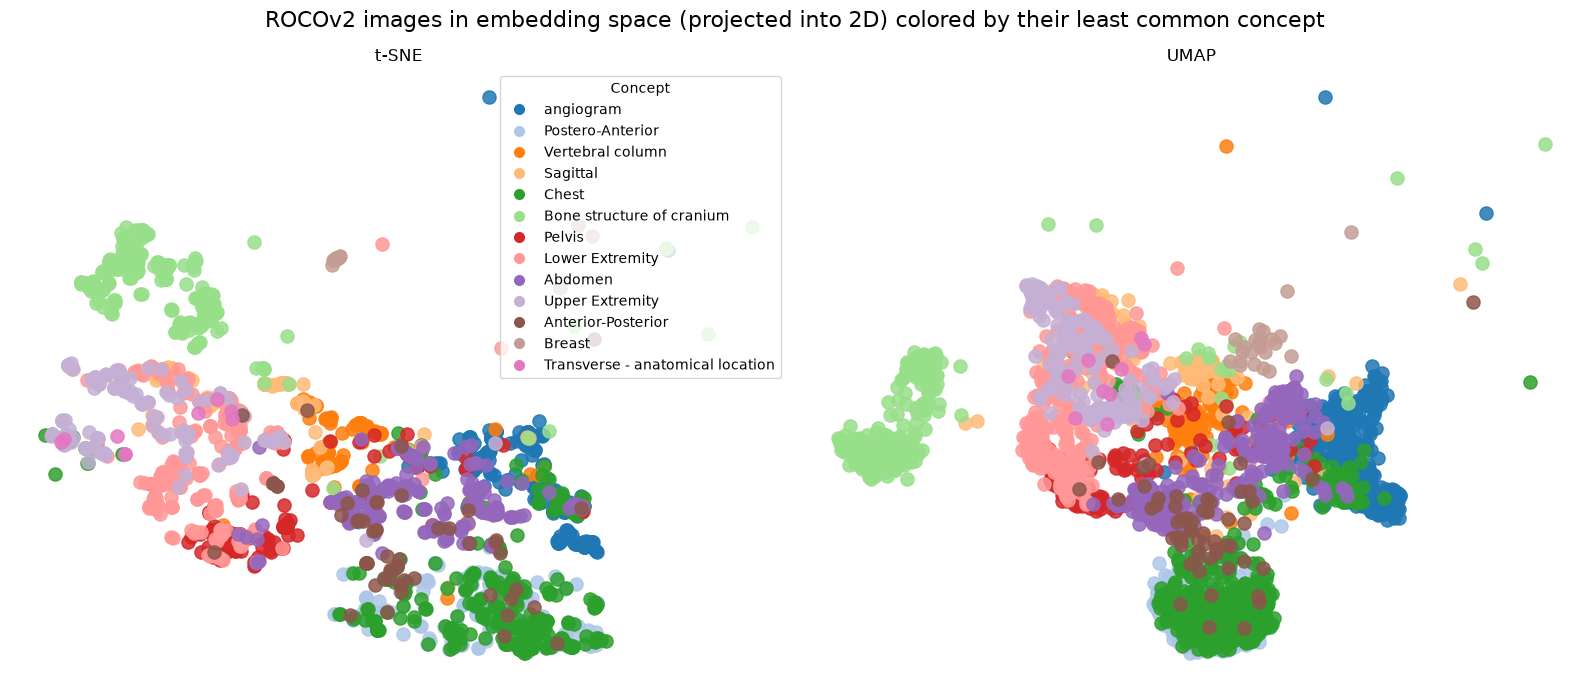

In [9]:
# images plotted in embedding space projected into 2d
# colored by least common concept in each list, filtering out image modalities 
# (since these are large clusters that dominate the visualization, and are already shown in modality visualization above)
samples = len(ds_roco)

embeddings = roco_image_embeddings.cpu().numpy()
concepts = cast(list[list[int]], ds_roco["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])
filter_concepts = set([ds_roco_cui.index(c) for c in [
    'X-Ray Computed Tomography', 'Plain x-ray', 'Ultrasonography', 
    'Magnetic Resonance Imaging', 'PET/CT scan', 'Computed tomography imaging - action',
    'Positron-Emission Tomography'
]])
concepts = [[c for c in concept_list if c not in filter_concepts] for concept_list in concepts]

# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = np.array([(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts]) # least common concept in each list
#concepts = np.array([(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts]) # most common concept in each list
embeddings = embeddings[concepts != -1][:samples]
concepts = concepts[concepts != -1][:samples]

tsne_embeddings = tsne_rad_image.transform(embeddings)
umap_embeddings = umap_rad_image.transform(embeddings)

unique_concepts = list(dict.fromkeys(concepts))
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, projected, title in zip(
    axes,
    [tsne_embeddings, umap_embeddings],
    ["t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(title)
    ax.set_axis_off()

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=ds_roco_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="Concept", loc="best")
fig.suptitle('ROCOv2 images in embedding space (projected into 2D) colored by their least common concept', fontsize=16)

plt.tight_layout()
plt.show()

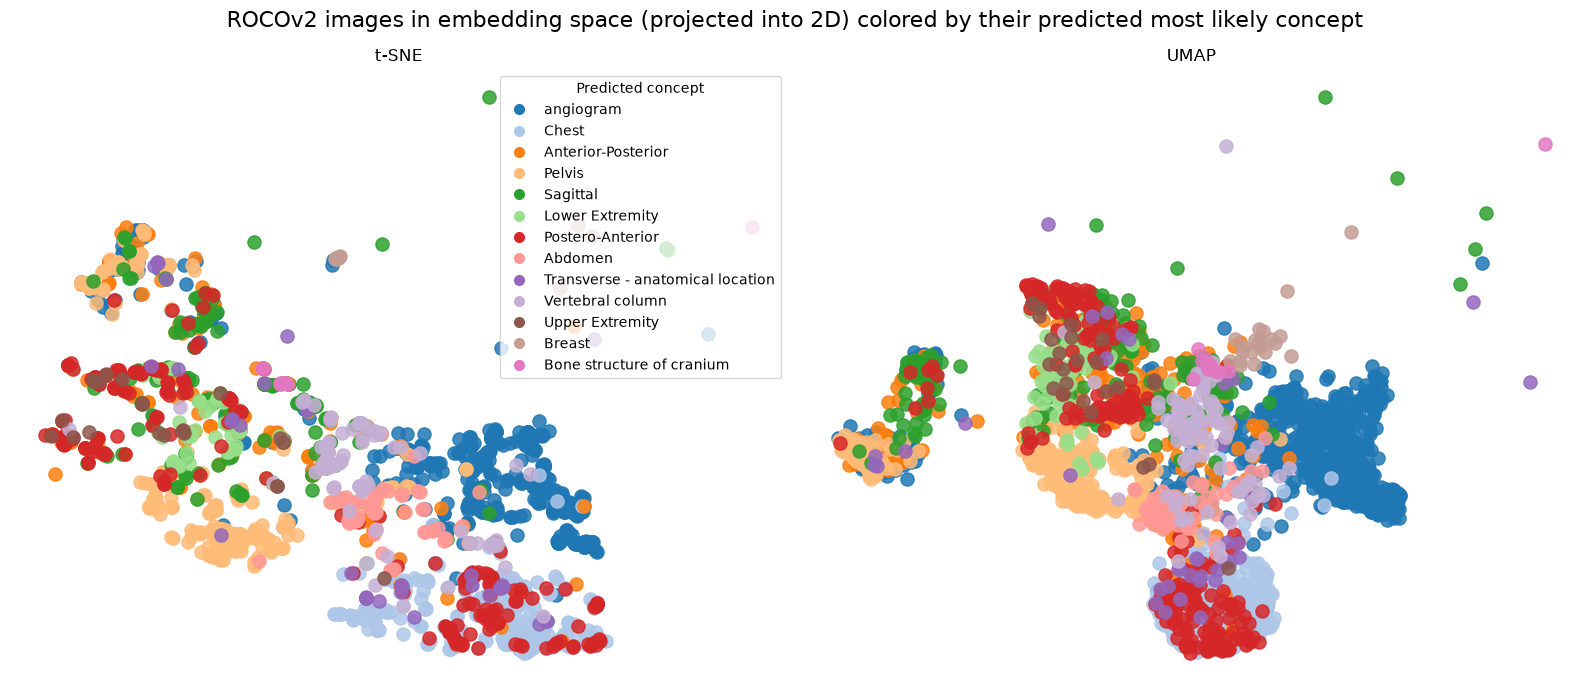

In [15]:
# images plotted in embedding space projected into 2d
# colored by predicted most likely concept out of concepts from last figure
samples = len(ds_roco)

embeddings = roco_image_embeddings.cpu().numpy()
# filter concepts to only those appearing in the previous figure; but do not filter embeddings, since we want to predict concepts for all images
concepts = cast(list[list[int]], ds_roco["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])
filter_concepts = set([ds_roco_cui.index(c) for c in [
    'X-Ray Computed Tomography', 'Plain x-ray', 'Ultrasonography', 
    'Magnetic Resonance Imaging', 'PET/CT scan', 'Computed tomography imaging - action',
    'Positron-Emission Tomography'
]])
concepts = [[c for c in concept_list if c not in filter_concepts] for concept_list in concepts]
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = np.array([(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts]) # least common concept in each list
#concepts = np.array([(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts]) # most common concept in each list
embeddings = embeddings[concepts != -1][:samples]
concepts = concepts[concepts != -1][:samples]
unique_concepts = list(dict.fromkeys(concepts))

filtered_concept_embeddings = roco_cui_embeddings.cpu().numpy()[unique_concepts]
filtered_cui = [ds_roco_cui[c] for c in unique_concepts]
most_likely_concepts = np.argmax(embeddings @ filtered_concept_embeddings.T, axis=1)
unique_concepts = list(dict.fromkeys(most_likely_concepts))

tsne_embeddings = tsne_rad_image.transform(embeddings)
umap_embeddings = umap_rad_image.transform(embeddings)

colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, projected, title in zip(
    axes,
    [tsne_embeddings, umap_embeddings],
    ["t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in most_likely_concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(title)
    ax.set_axis_off()

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=filtered_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="Predicted concept", loc="best")
fig.suptitle('ROCOv2 images in embedding space (projected into 2D) colored by their predicted most likely concept', fontsize=16)

plt.tight_layout()
plt.show()

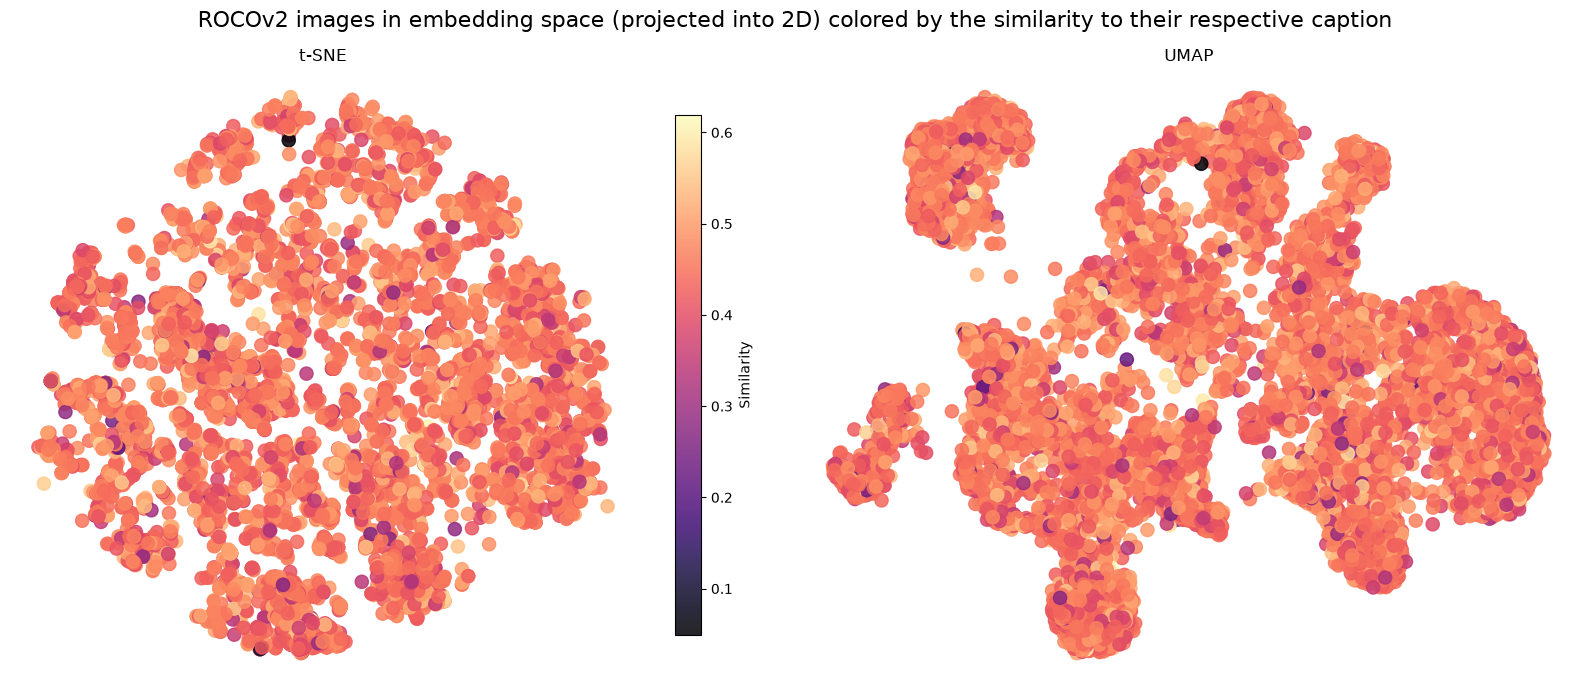

In [11]:
# images plotted in embedding space projected into 2d
# colored by similarity to respective embedded caption
samples = len(ds_roco)

images = roco_image_embeddings[:samples].cpu().numpy()
texts = roco_caption_embeddings[:samples].cpu().numpy()
similarities = np.sum(images * texts, axis=1)

tsne_embeddings = tsne_rad_image.transform(images)
umap_embeddings = umap_rad_image.transform(images)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, projected, title in zip(
    axes,
    [tsne_embeddings, umap_embeddings],
    ["t-SNE", "UMAP"],
):
    scatter = ax.scatter(
        projected[:, 0],
        projected[:, 1],
        c=similarities,
        cmap="magma",
        norm=Normalize(vmin=similarities.min(), vmax=similarities.max()),
        s=90,
        alpha=0.85,
    )
    ax.set_title(title)
    ax.set_axis_off()

fig.colorbar(
    scatter,
    ax=axes[0],
    label="Similarity",
    shrink=0.85,
)
fig.suptitle('ROCOv2 images in embedding space (projected into 2D) colored by the similarity to their respective caption', fontsize=16)

plt.tight_layout()
plt.show()

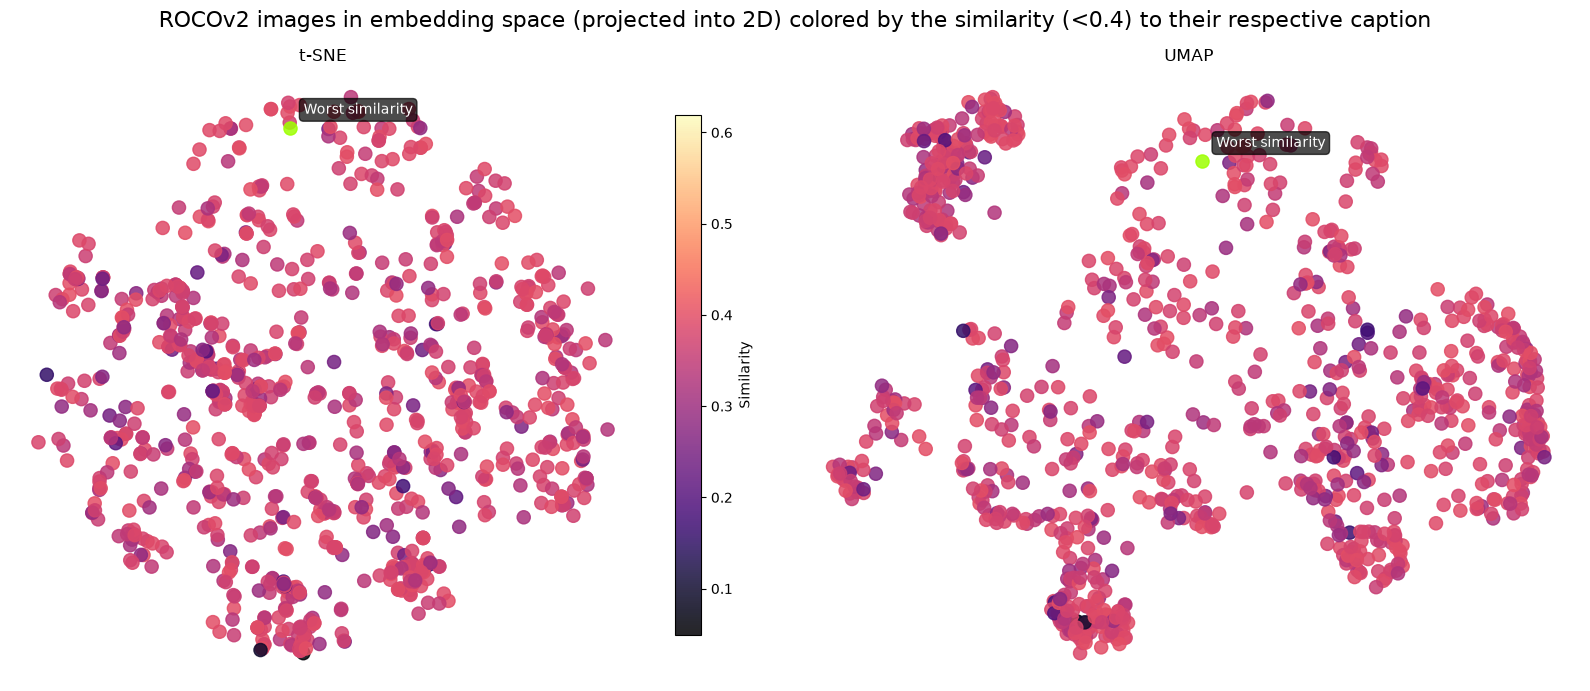

In [13]:
# images plotted in embedding space projected into 2d
# colored by similarity to respective embedded caption
samples = len(ds_roco)
similarity_threshold = 0.4

images = roco_image_embeddings[:samples].cpu().numpy()
texts = roco_caption_embeddings[:samples].cpu().numpy()
similarities = np.sum(images * texts, axis=1)
images = images[similarities < similarity_threshold]
filtered_similarities = similarities[similarities < similarity_threshold]

worst_sim = np.argmin(filtered_similarities)

tsne_embeddings = tsne_rad_image.transform(images)
umap_embeddings = umap_rad_image.transform(images)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, projected, title in zip(
    axes,
    [tsne_embeddings, umap_embeddings],
    ["t-SNE", "UMAP"],
):
    scatter = ax.scatter(
        np.delete(projected, worst_sim, axis=0)[:, 0],
        np.delete(projected, worst_sim, axis=0)[:, 1],
        c=np.delete(filtered_similarities, worst_sim, axis=0),
        cmap="magma",
        norm=Normalize(vmin=similarities.min(), vmax=similarities.max()),
        s=90,
        alpha=0.85,
    )
    _ = ax.scatter(
        projected[worst_sim, None, 0],
        projected[worst_sim, None, 1],
        c="#9DFF00",
        s=90,
        alpha=0.85,
    )
    # adding an arrow pointing to the worst similarity point
    ax.annotate(
        "Worst similarity",
        xy=(projected[worst_sim, 0], projected[worst_sim, 1]),
        xytext=(10, 10),
        textcoords="offset points",
        fontsize=10,
        color="white",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="black", alpha=0.7),
    )
    ax.set_title(title)
    ax.set_axis_off()

fig.colorbar(
    scatter,
    ax=axes[0],
    label="Similarity",
    shrink=0.85,
)
fig.suptitle(f'ROCOv2 images in embedding space (projected into 2D) colored by the similarity (<{similarity_threshold}) to their respective caption', fontsize=16)

plt.tight_layout()
plt.show()

Image-caption pair with the worst similarity and its nearest neighbors in UMAP projection of embedding space:


,Image,Similarity,Caption,Concepts
Worst,,0.0490,The location of the forceps minor.,Magnetic Resonance Imaging
Neighbor 1,,0.4282,Showing a sagittal section of a contrast MRI pituitary scan in patient demonstrating the Rathke’s cleft cyst and displaced pituitary tissue.,Magnetic Resonance Imaging
Neighbor 2,,0.4268,"Partial Spearman’s correlations between cerebrospinal fluid cortisol and regional brain volumes (adjusted for age and sex). There were significant negative partial correlations between baseline cerebrospinal fluid cortisol levels and the volumes of the amygdala, and the insula (adjusted for sex and age).",Magnetic Resonance Imaging

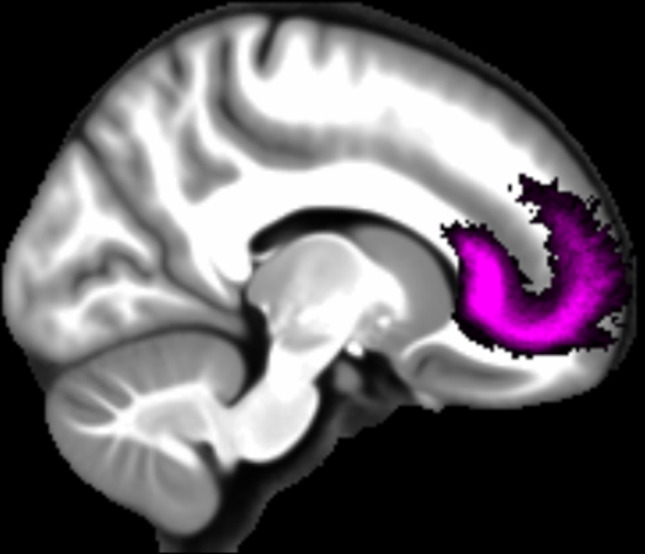
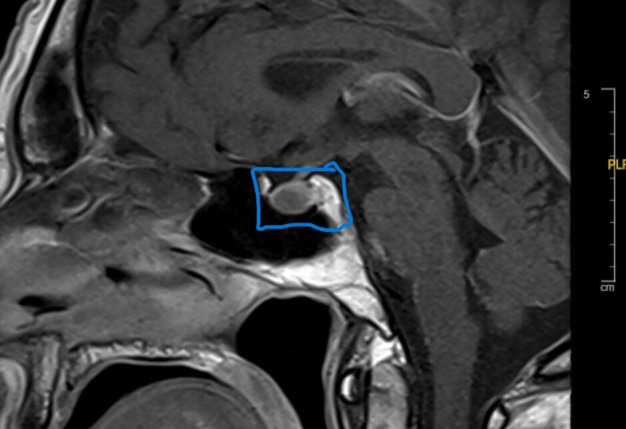
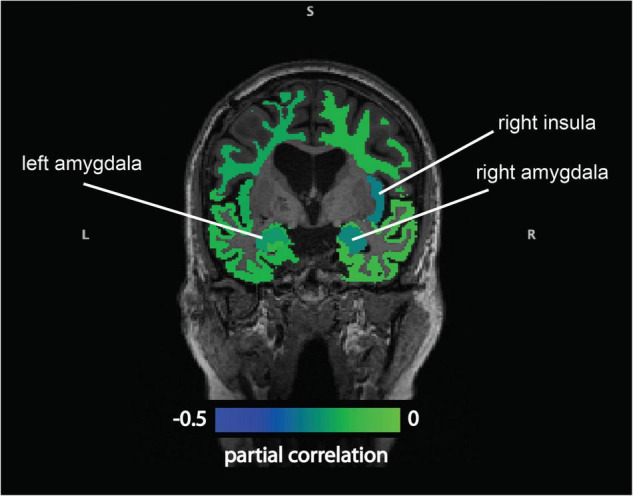

In [14]:
from base64 import b64encode
from html import escape
from io import BytesIO
from IPython.display import HTML, display

neighbors = 2
samples = len(ds_roco)

def show_table_of_roco_entries(idx: list[int], titles: list[str], similarities: list[float]):
    # we can just use HTML with IPython.display
    # so building an HTML table with a row for each entry
    # for styling we can use CSS
    rows = []
    for i, title, similarity in zip(idx, titles, similarities):
        e = ds_roco[int(i)]
        # temporarily saving image to buffer so we can Base64 encode it for embedding in HTML
        buffer = BytesIO()
        e["image"].save(buffer, format="PNG")
        rows.append(
            f"""
            <tr>
                <th>{escape(title)}</th>
                <td><img src="data:image/png;base64,{b64encode(buffer.getvalue()).decode()}" width="500"></td>
                <td>{escape(f'{similarity:.4f}')}</td>
                <td>{escape(e["caption"])}</td>
                <td>{escape(", ".join([ds_roco_cui[c] for c in e["concepts_manual"]]))}</td>
            </tr>
            """
        )

    display(
        HTML(
            f"""
            <style>
                .roco-table th, .roco-table td {{
                    border: 1px solid #999;
                    padding: 8px;
                    vertical-align: top;
                }}
                .roco-table thead th {{
                    background-color: blue;
                    color: white;
                    text-align: center;
                }}
                .roco-table tbody th {{
                    background-color: lightblue;
                    color: black;
                    font-weight: bold;
                    text-align: center;
                }}
                .roco-table td {{
                    background-color: white;
                    color: black;
                    text-align: left;
                }}
            </style>

            <table class="roco-table">
                <thead>
                    <tr>
                        <th></th>
                        <th>Image</th>
                        <th>Similarity</th>
                        <th>Caption</th>
                        <th>Concepts</th>
                    </tr>
                </thead>
                <tbody>
                    {''.join(rows)}
                </tbody>
            </table>
            """
        )
    )

images = roco_image_embeddings[:samples].cpu().numpy()
texts = roco_caption_embeddings[:samples].cpu().numpy()
similarities = np.sum(images * texts, axis=1)

umap_embeddings = umap_rad_image.transform(images)
worst_sim = np.argmin(similarities)
worst_sim_neighbors = np.argsort(np.sum((umap_embeddings - umap_embeddings[worst_sim]) ** 2, axis=1))[0:neighbors+1]

print("Image-caption pair with the worst similarity and its nearest neighbors in UMAP projection of embedding space:")
show_table_of_roco_entries(list(worst_sim_neighbors), ["Worst"] + [f"Neighbor {i+1}" for i in range(neighbors)], [similarities[i] for i in worst_sim_neighbors])